✅ Dataset loaded successfully!
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  
Training samples: 80000 | Testing samples: 20000

🚀 Training LogisticRegression...
✅ LogisticRegression trained and saved at: D:\Research work\Mplementation\Diabetes Prediction\saved_models_optuna\best_logisticregression_pipeline.joblib
   Accuracy=0.960

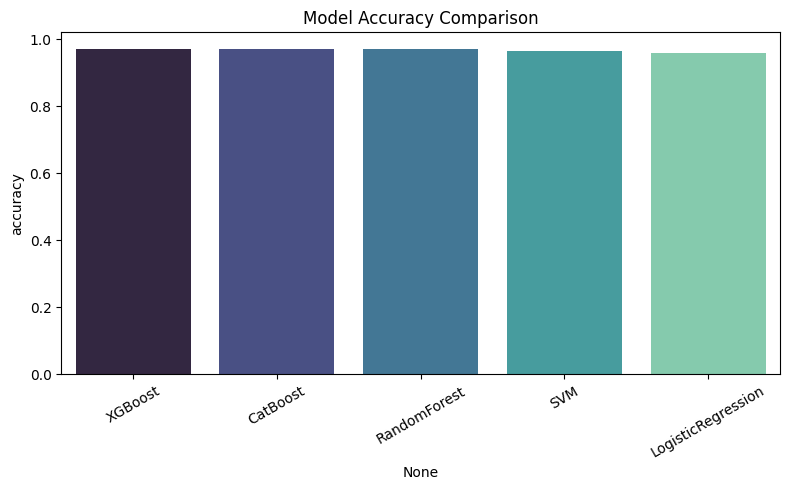


🏆 Best model: XGBoost


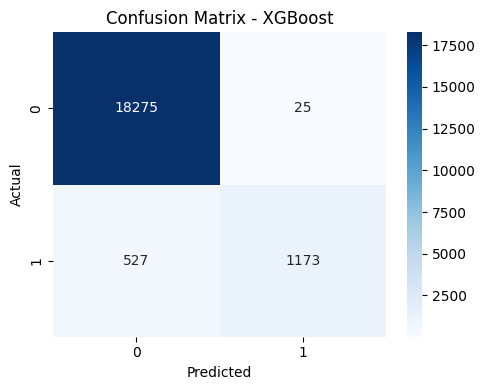

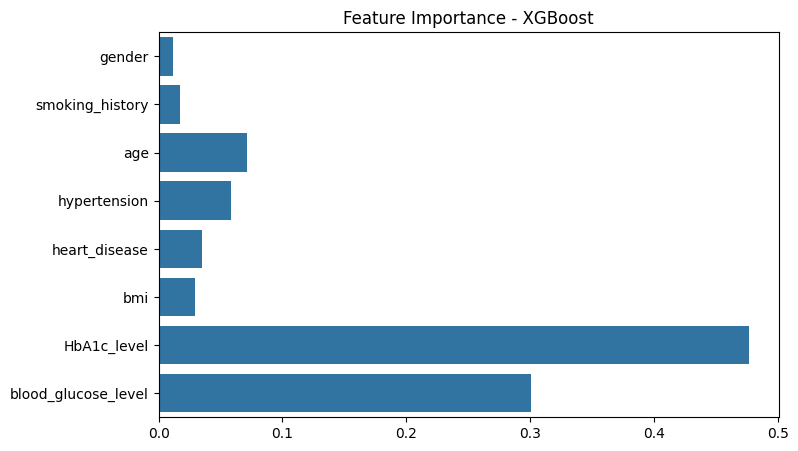


💾 Saved best model for Streamlit UI: D:\Research work\Mplementation\Diabetes Prediction\saved_models_optuna\best_diabetes_model.pkl

✅ All models trained, evaluated, and saved successfully!


In [2]:
# ============================================================
# 🩺 Diabetes Prediction — Universal Model Trainer (UI Compatible)
# Author: Ankit Thakur
# ============================================================ 

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import joblib
import pickle
import warnings
warnings.filterwarnings("ignore")

# ============================================================
# 1️⃣ LOAD DATASET
# ============================================================
df = pd.read_csv(r"D:\Research work\Mplementation\Diabetes Prediction\diabetes_prediction_dataset.csv")
print("✅ Dataset loaded successfully!")
print(df.head())

# ============================================================
# 2️⃣ FEATURE-TARGET SPLIT
# ============================================================
X = df.drop('diabetes', axis=1)
y = df['diabetes']

categorical_features = ['gender', 'smoking_history']
numeric_features = [col for col in X.columns if col not in categorical_features]

# ============================================================
# 3️⃣ TRAIN-TEST SPLIT
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Training samples: {len(X_train)} | Testing samples: {len(X_test)}")

# ============================================================
# 4️⃣ PREPROCESSOR (for all except CatBoost)
# ============================================================
preprocessor = ColumnTransformer([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), categorical_features),
    ('num', StandardScaler(), numeric_features)
])

# ============================================================
# 5️⃣ DEFINE MODELS
# ============================================================
models = {
    "LogisticRegression": Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "RandomForest": Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(n_estimators=200, random_state=42))
    ]),
    "SVM": Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', SVC(kernel='rbf', probability=True, random_state=42))
    ]),
    "XGBoost": Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=5,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric='logloss'
        ))
    ]),
    # CatBoost handles categorical directly, no preprocessor needed
    "CatBoost": CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        verbose=0,
        random_seed=42
    )
}

# ============================================================
# 6️⃣ TRAIN & EVALUATE EACH MODEL
# ============================================================
results = {}
MODEL_DIR = r"D:\Research work\Mplementation\Diabetes Prediction\saved_models_optuna"

for name, model in models.items():
    print(f"\n🚀 Training {name}...")

    # Handle CatBoost separately (no pipeline)
    if name == "CatBoost":
        model.fit(X_train, y_train, cat_features=categorical_features)
        y_pred = model.predict(X_test)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    # Save model
    model_path = f"{MODEL_DIR}\\best_{name.lower()}_pipeline.joblib"
    joblib.dump(model, model_path)

    results[name] = {
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "path": model_path
    }

    print(f"✅ {name} trained and saved at: {model_path}")
    print(f"   Accuracy={acc:.4f}, Precision={prec:.4f}, Recall={rec:.4f}, F1={f1:.4f}")

# ============================================================
# 7️⃣ RESULTS SUMMARY TABLE
# ============================================================
results_df = pd.DataFrame(results).T.sort_values(by="accuracy", ascending=False)
print("\n===== Model Comparison =====")
print(results_df)

plt.figure(figsize=(8, 5))
sns.barplot(x=results_df.index, y=results_df["accuracy"], palette="mako")
plt.title("Model Accuracy Comparison")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# ============================================================
# 8️⃣ CONFUSION MATRIX FOR BEST MODEL
# ============================================================
best_model_name = results_df.index[0]
print(f"\n🏆 Best model: {best_model_name}")

best_model_path = results[best_model_name]["path"]
best_model = joblib.load(best_model_path)

if best_model_name == "CatBoost":
    y_pred_best = best_model.predict(X_test)
else:
    y_pred_best = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# ============================================================
# 9️⃣ FEATURE IMPORTANCE (if available)
# ============================================================
try:
    if best_model_name == "CatBoost":
        importances = best_model.get_feature_importance()
    else:
        importances = best_model.named_steps['classifier'].feature_importances_

    feature_names = categorical_features + numeric_features
    plt.figure(figsize=(8, 5))
    sns.barplot(x=importances, y=feature_names)
    plt.title(f"Feature Importance - {best_model_name}")
    plt.show()
except Exception as e:
    print(f"⚠ Feature importance not available: {e}")

# ============================================================
# 🔐 SAVE BEST MODEL AS .PKL FOR UI
# ============================================================
best_pkl_path = f"{MODEL_DIR}\\best_diabetes_model.pkl"
with open(best_pkl_path, "wb") as f:
    pickle.dump(best_model, f)
print(f"\n💾 Saved best model for Streamlit UI: {best_pkl_path}")

print("\n✅ All models trained, evaluated, and saved successfully!")
